<a href="https://colab.research.google.com/github/gomezllari/.json/blob/main/Desafio_P%C3%B3s_Tech_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd

# Se o arquivo estiver na mesma pasta do seu código:
df = pd.read_csv('insurance.csv')

print(df.head())

         id;satisfaction_level;last_evaluation;average_montly_hours;time_spend_company;Work_accident;left;promotion_last_5years;salary;num_project;depto
1;0 38;0                         53;157;3;0;1;0;low;2;sales                                                                                             
2;0 8;0                       86;262;6;0;1;0;medium;5;sales                                                                                             
3;0 11;0                      88;272;4;0;1;0;medium;6;sales                                                                                             
4;0 72;0                         87;223;5;0;1;0;low;5;sales                                                                                             
5;0 37;0                         52;159;3;0;1;0;low;2;sales                                                                                             


In [6]:
import pandas as pd

# 1. Carregar o arquivo (ajuste o separador se necessário)
df = pd.read_csv('insurance.csv', sep=None, engine='python')

# 2. Converter colunas numéricas que vieram com vírgula para ponto
for col in ['satisfaction_level', 'last_evaluation']:
    if df[col].dtype == 'object':
        df[col] = df[col].astype(str).str.replace(',', '.').astype(float)

# 3. Remover a coluna 'id', pois ela não traz informação útil para prever a saída
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# Ver as primeiras linhas limpas
print(df.head())
print(df.info())

   satisfaction_level  last_evaluation  average_montly_hours  \
0                0.38             0.53                   157   
1                0.80             0.86                   262   
2                0.11             0.88                   272   
3                0.72             0.87                   223   
4                0.37             0.52                   159   

   time_spend_company  Work_accident  left  promotion_last_5years  salary  \
0                   3              0     1                      0     low   
1                   6              0     1                      0  medium   
2                   4              0     1                      0  medium   
3                   5              0     1                      0     low   
4                   3              0     1                      0     low   

   num_project  depto  
0            2  sales  
1            5  sales  
2            6  sales  
3            5  sales  
4            2  sales  
<class '

In [7]:
from sklearn.model_selection import train_test_split

# 1. Separar o que é alvo (y) do que são as características (X)
X = df.drop(columns=['left'])
y = df['left']

# 2. Dividir os dados: 80% para treinar o modelo e 20% para testar no final
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Vamos ver se deu certo imprimindo o tamanho dos pedaços
print(f"Total de linhas originais: {len(df)}")
print(f"Linhas para treino: {len(X_train)}")
print(f"Linhas para teste: {len(X_test)}")

Total de linhas originais: 14999
Linhas para treino: 11999
Linhas para teste: 3000


In [8]:
# Transformar as colunas de texto (salary e depto) em colunas numéricas (0 ou 1)
X_encoded = pd.get_dummies(X, columns=['salary', 'depto'], drop_first=True)

# Vamos ver como ficou o formato de X agora
print(f"Número de colunas antes: {X.shape[1]}")
print(f"Número de colunas agora (com o texto transformado): {X_encoded.shape[1]}")
print(X_encoded.head(2))

Número de colunas antes: 9
Número de colunas agora (com o texto transformado): 18
   satisfaction_level  last_evaluation  average_montly_hours  \
0                0.38             0.53                   157   
1                0.80             0.86                   262   

   time_spend_company  Work_accident  promotion_last_5years  num_project  \
0                   3              0                      0            2   
1                   6              0                      0            5   

   salary_low  salary_medium  depto_RandD  depto_accounting  depto_hr  \
0        True          False        False             False     False   
1       False           True        False             False     False   

   depto_management  depto_marketing  depto_product_mng  depto_sales  \
0             False            False              False         True   
1             False            False              False         True   

   depto_support  depto_technical  
0          False       

In [10]:
X_encoded = pd.get_dummies(X, columns=['salary', 'depto'], drop_first=True)

In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Transformar o texto em colunas numéricas (criando o df_encoded do zero aqui)
df_encoded = pd.get_dummies(df, columns=['salary', 'depto'], drop_first=True)

# 2. Separar características (X) e alvo (y = left)
X = df_encoded.drop(columns=['left'])
y = df_encoded['left']

# 3. Dividir em Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Normalizar os dados (a nossa "régua")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Tudo pronto e normalizado com sucesso!")
print(f"Formato de X_train_scaled: {X_train_scaled.shape}")

Tudo pronto e normalizado com sucesso!
Formato de X_train_scaled: (11999, 18)


In [13]:
from sklearn.tree import DecisionTreeClassifier

# 1. Criar o modelo de Árvore de Decisão
# (O random_state=42 garante que o resultado seja o mesmo se você rodar de novo)
modelo = DecisionTreeClassifier(random_state=42)

# 2. Treinar o modelo usando os dados de TREINO (X_train_scaled e y_train)
modelo.fit(X_train_scaled, y_train)

print("Modelo treinado com sucesso! O robô já aprendeu os padrões.")

Modelo treinado com sucesso! O robô já aprendeu os padrões.


In [14]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Pedir para o modelo fazer previsões usando os dados de teste que ele NÃO conhece
previsoes = modelo.predict(X_test_scaled)

# 2. Calcular a precisão geral (quantos % ele acertou no total)
precisao = accuracy_score(y_test, previsoes)

print(f"Taxa de Acerto (Precisão) do Modelo: {precisao * 100:.2f}%")

# 3. Ver um relatório detalhado (acertos por categoria: quem ficou vs quem saiu)
print("\nRelatório Detalhado:")
print(classification_report(y_test, previsoes))

Taxa de Acerto (Precisão) do Modelo: 97.60%

Relatório Detalhado:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      2286
           1       0.94      0.96      0.95       714

    accuracy                           0.98      3000
   macro avg       0.96      0.97      0.97      3000
weighted avg       0.98      0.98      0.98      3000



In [15]:
import pandas as pd

# 1. Pegar a importância de cada coluna calculada pelo modelo
importancias = modelo.feature_importances_
colunas = X.columns

# 2. Juntar tudo numa tabela organizadinha e ordenar da mais importante para a menos importante
sns.barplot(x='Importancia', y='Caracteristica', data=df_importancia, palette='viridis', hue='Caracteristica', legend=False)df_importancia = df_importancia.sort_values(by='Importancia', ascending=False)

# 3. Mostrar o resultado
print("O que mais pesa na decisão do funcionário (do mais importante para o menos):")
print(df_importancia)

O que mais pesa na decisão do funcionário (do mais importante para o menos):
           Caracteristica  Importancia
0      satisfaction_level     0.503399
1         last_evaluation     0.150848
3      time_spend_company     0.125170
6             num_project     0.105916
2    average_montly_hours     0.094177
7              salary_low     0.003378
17        depto_technical     0.003330
16          depto_support     0.003163
8           salary_medium     0.002843
15            depto_sales     0.002565
13        depto_marketing     0.001311
4           Work_accident     0.001148
10       depto_accounting     0.000919
12       depto_management     0.000805
9             depto_RandD     0.000385
11               depto_hr     0.000362
5   promotion_last_5years     0.000279
14      depto_product_mng     0.000000


/tmp/ipykernel_2089/362601356.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Caracteristica', data=df_importancia, palette='viridis')


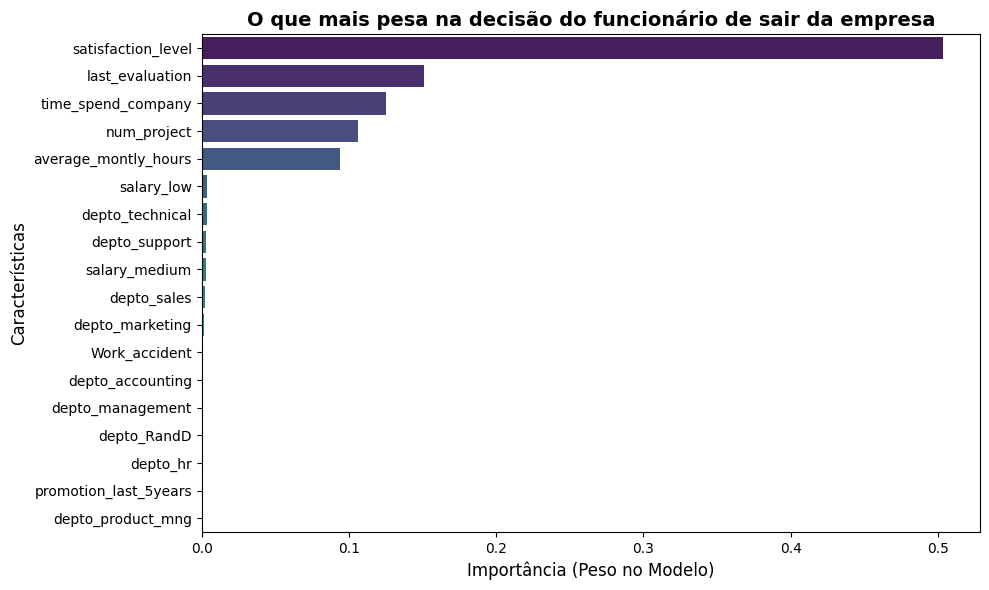

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
plt.figure(figsize=(10, 6))

# Criar o gráfico de barras horizontais
sns.barplot(x='Importancia', y='Caracteristica', data=df_importancia, palette='viridis')

# Adicionar título e rótulos
plt.title('O que mais pesa na decisão do funcionário de sair da empresa', fontsize=14, fontweight='bold')
plt.xlabel('Importância (Peso no Modelo)', fontsize=12)
plt.ylabel('Características', fontsize=12)

# Mostrar o gráfico na tela
plt.tight_layout()
plt.show()

In [17]:
import joblib

# Salvar o modelo treinado num arquivo chamado 'modelo_rh.pkl'
joblib.dump(modelo, 'modelo_rh.pkl')

print("Projeto concluído! Modelo salvo com sucesso no seu computador como 'modelo_rh.pkl'.")

Projeto concluído! Modelo salvo com sucesso no seu computador como 'modelo_rh.pkl'.
